In [3]:
import scanpy as sc
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
adata = sc.read_h5ad("../output/celldive_protein_matrix_celltypes.h5ad")
adata

AnnData object with n_obs × n_vars = 926006 × 23
    obs: 'cell_id', 'area', 'centroid_x', 'centroid_y', 'qc_label', 'is_clean', 'cell_type'
    uns: 'background_estimate', 'background_percentile', 'binary_threshold', 'binary_thresholds', 'cell_type_counts', 'cell_type_rules', 'data_source', 'qc_gates', 'sample_id'
    obsm: 'spatial'
    layers: 'binary'

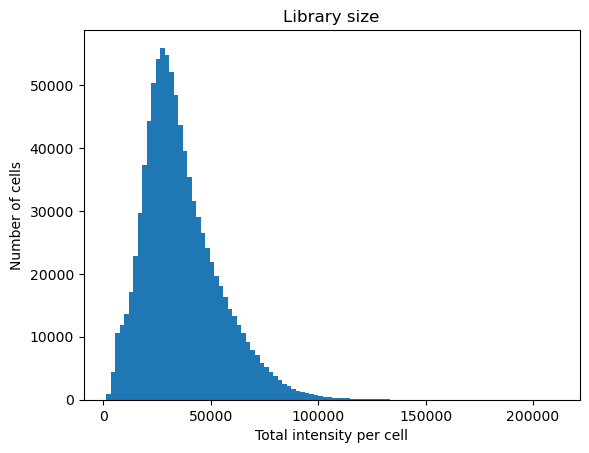

In [4]:
cell_sums = np.array(adata.X.sum(axis=1)).flatten()
plt.hist(cell_sums, bins=100)
plt.xlabel("Total intensity per cell")
plt.ylabel("Number of cells")
plt.title("Library size")
plt.show()

## Why arcsinh and scale?

CellDIVE mean intensities are skewed: most cells sit near background, a few are extremely bright. PCA / neighbors / UMAP use distances, so those bright cells would otherwise dominate.

- **`arcsinh(X / cofactor)`** — CyTOF/flow-style transform. Values ≪ *c* stay almost linear; values ≫ *c* become log-like. Better match for continuous fluorescence than `log1p`.
- **`sc.pp.scale(..., max_value=10)`** — z-score each marker so a bright channel (DAPI, PANCK) does not drown a dim one (CD3E). Clip at ±10 so a few extreme cells do not pull PCA.

Keep **raw** for plotting, thresholds, and cell typing. Put the **scaled** matrix in `adata.X` for PCA / UMAP.

### Cofactor

`150` is a flow-cytometry convention, not estimated from this dataset. CyTOF counts often use `5`; fluorescence often uses `150`–`200`. Choose *c* near typical marker background/noise:

- too small → background is stretched
- too large → real positives barely move

Check a few markers at `c = 5, 50, 150, 500`. Per-marker background in `adata.uns["background_estimate"]` is a data-driven starting point.

### Layers (this cell, in memory only)

| Layer | Contents |
|---|---|
| `raw` | continuous intensities before transform |
| `arcsinh` | after `arcsinh(X / 150)` |
| `scaled` | z-scored (also current `adata.X`) |

These copies are **not** written to disk unless you `write_h5ad`. The file loaded above only has `layers["binary"]`. Do not run this cell on the UMAP/Leiden `.h5ad` or you will double-transform.

In [5]:
cofactor = 150.0
adata.layers["raw"] = adata.X.copy()
adata.X = np.arcsinh(adata.X / cofactor)
adata.layers["arcsinh"] = adata.X.copy()
sc.pp.scale(adata, max_value=10)
adata.layers["scaled"] = adata.X.copy()
adata

AnnData object with n_obs × n_vars = 926006 × 23
    obs: 'cell_id', 'area', 'centroid_x', 'centroid_y', 'qc_label', 'is_clean', 'cell_type'
    var: 'mean', 'std'
    uns: 'background_estimate', 'background_percentile', 'binary_threshold', 'binary_thresholds', 'cell_type_counts', 'cell_type_rules', 'data_source', 'qc_gates', 'sample_id'
    obsm: 'spatial'
    layers: 'binary', 'raw', 'arcsinh', 'scaled'

## Transform QC: raw vs arcsinh vs scaled

These plots are how you judge **cofactor = 150**, not UMAP.

Each row is a marker; columns are `layers['raw']`, `layers['arcsinh']`, `layers['scaled']`. Overlays are rule-based types you already trust:

- **CD8_T** — should be high CD3E / CD8a, low PANCK / EPCAM
- **Epithelial_EPCAM** — the reverse
- **Fibroblast** — high VIM relative to those lineage markers

**Arcsinh (cofactor):** background stays a tight peak; positives pull into a shoulder. If negatives look smeared, *c* is too small. If T cells barely move in CD3E, *c* is too large — try `5, 50, 150, 500` in the cell above and re-run this plot.

**Scaled:** each marker is roughly mean 0, variance 1. A few values stuck at **+10** (bright tail) is expected; the low side often never hits −10. Do not read scaled panels as biology — they only check that z-scoring / clipping behaved.

Uses the named layers, so it is safe even though `adata.X` is already scaled.

In [ ]:
missing = [k for k in ("raw", "arcsinh", "scaled") if k not in adata.layers]
if missing:
    raise ValueError(f"Run the transform cell first; missing layers: {missing}")

MARKERS = [m for m in ("CD3E", "CD8a", "PANCK", "EPCAM", "VIM") if m in adata.var_names]
STAGES = ("raw", "arcsinh", "scaled")
TYPE_COLORS = {"CD8_T": "C0", "Epithelial_EPCAM": "C1", "Fibroblast": "C2"}
types_present = [t for t in TYPE_COLORS if t in set(adata.obs["cell_type"].astype(str))]

fig, axes = plt.subplots(
    len(MARKERS), len(STAGES), figsize=(12, 2.6 * len(MARKERS)), sharey=False
)
if len(MARKERS) == 1:
    axes = np.array([axes])

for i, marker in enumerate(MARKERS):
    col = adata.var_names.get_loc(marker)
    for j, stage in enumerate(STAGES):
        ax = axes[i, j]
        vals = np.asarray(adata.layers[stage][:, col]).ravel()
        lo, hi = np.nanpercentile(vals, [0.5, 99.5])
        if not np.isfinite(lo) or not np.isfinite(hi) or lo == hi:
            lo, hi = float(np.nanmin(vals)), float(np.nanmax(vals))
        bins = np.linspace(lo, hi, 80)
        ax.hist(vals, bins=bins, density=True, color="0.75", alpha=0.85, label="all cells")
        for ct in types_present:
            mask = adata.obs["cell_type"].astype(str).to_numpy() == ct
            ax.hist(
                vals[mask],
                bins=bins,
                density=True,
                histtype="step",
                linewidth=1.4,
                color=TYPE_COLORS[ct],
                label=ct,
            )
        ax.set_xlim(lo, hi)
        if i == 0:
            ax.set_title(stage)
        if j == 0:
            ax.set_ylabel(marker)
        if i == len(MARKERS) - 1:
            ax.set_xlabel("intensity")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", frameon=False)
fig.suptitle(f"Marker distributions before/after transform (cofactor={cofactor:g})", y=1.01)
fig.tight_layout()
plt.show()

Xs = np.asarray(adata.layers["scaled"])
print(f"scaled min={Xs.min():.2f}  max={Xs.max():.2f}")
print(f"fraction clipped at +10: {(Xs >= 10).mean():.4%}")
print(f"fraction clipped at -10: {(Xs <= -10).mean():.4%}")

In [6]:
adata.X

array([[-2.5799067 , -0.40833265, -0.46899974, ..., -0.10369191,
        -0.01367971, -3.2321007 ],
       [ 0.72948176,  1.0047032 , -0.7244347 , ..., -0.5550969 ,
         0.85272527, -0.50486594],
       [ 0.6992585 ,  1.3660845 ,  0.3243823 , ...,  0.16927874,
         0.6738617 , -0.24425097],
       ...,
       [-2.1692958 , -0.15279919, -0.5761647 , ..., -1.4125509 ,
        -0.55876297, -1.0492826 ],
       [-2.4548888 , -0.2899197 , -0.46618366, ..., -1.369818  ,
        -0.55876297, -1.2238405 ],
       [-2.669141  , -0.23691206, -0.42961943, ..., -1.3791639 ,
        -0.5550302 , -1.9689338 ]], shape=(926006, 23), dtype=float32)

In [11]:
np.max(adata.X)

np.float32(10.0)

In [12]:
adata

AnnData object with n_obs × n_vars = 926006 × 23
    obs: 'cell_id', 'area', 'centroid_x', 'centroid_y', 'qc_label', 'is_clean', 'cell_type', 'leiden_r15', 'leiden'
    var: 'mean', 'std'
    uns: 'background_estimate', 'background_percentile', 'binary_threshold', 'binary_thresholds', 'cell_type_counts', 'cell_type_rules', 'data_source', 'leiden_r15', 'neighbors', 'pca', 'qc_gates', 'sample_id', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'binary', 'raw'
    obsp: 'connectivities', 'distances'